# Continuous Bag-of-Words (CBOW / BoW): Multi-Corpus Training, Vector Analogies & Visualizations

This notebook provides an end-to-end implementation and comprehensive evaluation of the **Continuous Bag-of-Words (CBOW / BoW)** architecture trained on a multi-document literary benchmark (11 classic works in `./corpuses`):

1. **Continuous Bag-of-Words with Negative Sampling**: Predicts the central target word given the mean embedding vector of context words within the sliding window, optimizing log-sigmoid negative sampling loss (Mikolov et al., 2013).
2. **Strict Document Boundary Protection**: Each book is tokenized and processed independently. Context windows **never cross document boundaries**, eliminating cross-book sample contamination.
3. **Analytical Similarity Verification**: Comparison of intra-book thematic pairs against cross-book negative controls.
4. **16x16 Modular Heatmap**: Visualizes high intra-universe similarity and near-zero cross-universe correlation across 4 distinct literary universes.
5. **Interactive 3D WebGL Pointplot**: Full 360° rotatable 3D embedding space rendered with Plotly.
6. **2D PCA Projection Map**: Thematic clusters and relationship vectors in 2D space.
7. **Vector Analogy Arithmetic ($A : B :: C : ?$)**: Linear compositionality demonstration (e.g. $\vec{w}_{\text{king}} - \vec{w}_{\text{man}} + \vec{w}_{\text{woman}} \approx \vec{w}_{\text{queen}}$).
8. **Parallel Vector Offset Visualization**: Visual confirmation that semantic relations (like gender) correspond to consistent spatial translations.


In [1]:
import os
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
import plotly.graph_objects as go
import plotly.io as pio
import torch

# Configure Plotly renderer
pio.renderers.default = "plotly_mimetype+notebook_connected"

# Resolve repository root directory
repo_root = Path.cwd().resolve()
if repo_root.name == "notebooks":
    repo_root = repo_root.parent

corpus_dir = str(repo_root / "corpuses")
logs_dir = str(repo_root / "logs")
embeddings_dir = str(repo_root / "embeddings")

if str(repo_root) not in sys.path:
    sys.path.insert(0, str(repo_root))

# Import BoW architecture, corpus hook, and centralized logging
from w2v import BoW, ensure_nltk_gutenberg_corpora, setup_logging

# Initialize execution logging
log_file = setup_logging(log_dir=logs_dir)

# Set random seeds for reproducibility
np.random.seed(42)
torch.manual_seed(42)

print(f"PyTorch version: {torch.__version__}")
print(f"Compute device: {'CUDA (GPU)' if torch.cuda.is_available() else 'CPU'}")
print(f"Repository root: {repo_root}")
print(f"Corpus directory: {corpus_dir}")
print(f"Log file active: {log_file}")


2026-10-24 19:17:53 [INFO] [SkipGram]: Logging initialized. Output file: C:\Users\utente\repos\word2vec\logs\word2vec_20261024_191753.log


PyTorch version: 2.5.1+cu121
Compute device: CUDA (GPU)
Repository root: C:\Users\utente\repos\word2vec
Corpus directory: C:\Users\utente\repos\word2vec\corpuses
Log file active: C:\Users\utente\repos\word2vec\logs\word2vec_20261024_191753.log


## 1. Corpus Synchronization & Continuous Bag-of-Words Training (10 Epochs)

### A. Pre-Training Corpus Synchronization Hook
The `ensure_nltk_gutenberg_corpora` hook scans `corpus_dir`:
- Pre-existing custom files (such as `portrait_of_dorian_gray.txt`) are **fully preserved**.
- Any missing classic books from NLTK Gutenberg are automatically downloaded as a **delta**.

### B. Document Boundary Protection
`BoWDataset` processes each document independently: the context bag **never** wraps across document boundaries.


In [2]:
# Ensure all target NLTK corpora are present
ensure_nltk_gutenberg_corpora(corpus_dir)

# Initialize Continuous Bag-of-Words (BoW) engine
bow_model = BoW(
    corpus_dir=corpus_dir,
    embedding_dim=128,
    window_size=2,
    n_negative=5,
    min_count=3,
    tied_weights=True,
    sync_corpora_hook=True,
)

print(f"\nLoaded documents: {len(bow_model.documents)}")
print(f"Total extracted tokens: {len(bow_model.tokens):,}")
print(f"Vocabulary size: {bow_model.dataset.vocab_size:,} unique words")
print(f"BoW training samples: {len(bow_model.dataset):,} (strictly intra-document)")

# Train the model for 10 epochs
history = bow_model.train(epochs=10, batch_size=512, lr=0.005)


2026-10-24 19:17:53 [INFO] [DataDownloader]: Scanning directory 'C:\Users\utente\repos\word2vec\corpuses' for NLTK Gutenberg corpora...


2026-10-24 19:17:53 [INFO] [DataDownloader]: Found 11 pre-existing file(s) in folder (preserved).


2026-10-24 19:17:53 [INFO] [DataDownloader]: Identified delta of 8 missing corpus file(s) to fetch from NLTK: ['chesterton-ball.txt', 'shakespeare-caesar.txt', 'blake-poems.txt', 'whitman-leaves.txt', 'bryant-stories.txt', 'burgess-busterbrown.txt', 'edgeworth-parents.txt', 'bible-kjv.txt']


2026-10-24 19:17:53 [INFO] [DataDownloader]: Downloaded delta corpus file: 'chesterton-ball.txt' (457450 characters).


2026-10-24 19:17:53 [INFO] [DataDownloader]: Downloaded delta corpus file: 'shakespeare-caesar.txt' (112310 characters).


2026-10-24 19:17:53 [INFO] [DataDownloader]: Downloaded delta corpus file: 'blake-poems.txt' (38153 characters).


... (45 outputs left out)

2026-10-24 19:20:50 [INFO] [BoW]: Epoch [8/10] - Average Loss: 4.0343 across 4247 batches.


2026-10-24 19:21:12 [INFO] [BoW]: Epoch [9/10] - Average Loss: 4.0291 across 4247 batches.


2026-10-24 19:21:34 [INFO] [BoW]: Epoch [10/10] - Average Loss: 4.0248 across 4247 batches.


2026-10-24 19:21:34 [INFO] [BoW]: BoW Training finished successfully in 211.85 seconds (21.18 s/epoch).


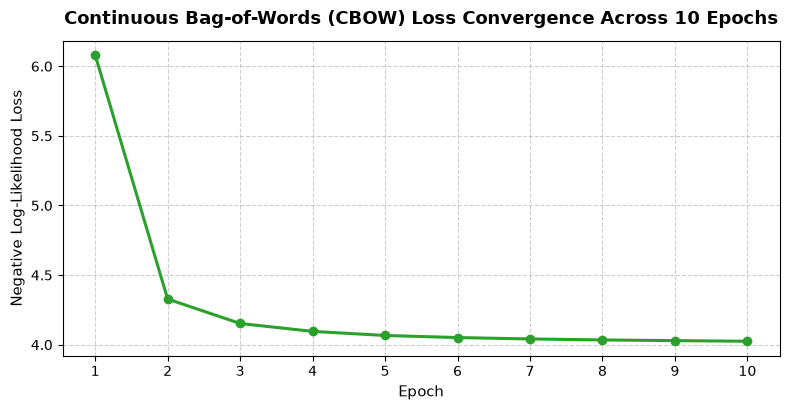

In [3]:
# Plot Negative Log-Likelihood Loss Convergence
plt.figure(figsize=(8, 4.2))
plt.plot(range(1, len(history) + 1), history, marker="o", color="#2ca02c", linewidth=2.2, markersize=6)
plt.title("Continuous Bag-of-Words (CBOW) Loss Convergence Across 10 Epochs", fontsize=13, fontweight="bold", pad=12)
plt.xlabel("Epoch", fontsize=11)
plt.ylabel("Negative Log-Likelihood Loss", fontsize=11)
plt.grid(True, linestyle="--", alpha=0.6)
plt.xticks(range(1, len(history) + 1))
plt.tight_layout()
plt.show()


## 2. Analytical Verification: Do Embeddings Truly Reflect Semantic Associations?

To evaluate the learned representation quality:
1. **Intra-Book Literary Pairs**: Major character names and key thematic terms co-occurring in the same book (e.g. `dorian`-`gray`, `captain`-`ahab`, `white`-`rabbit`).
2. **Negative Controls**: Word pairs drawn from entirely different books (e.g. `dorian` vs `ahab`, `alice` vs `macbeth`), which should exhibit low or near-zero similarity.


In [4]:
def get_cosine_sim(model, w1: str, w2: str) -> float:
    e1 = model.get_embedding(w1)
    e2 = model.get_embedding(w2)
    if e1 is None or e2 is None:
        return float("nan")
    return float(np.dot(e1, e2) / (np.linalg.norm(e1) * np.linalg.norm(e2)))

test_pairs = [
    # Dorian Gray pairs
    ("lord", "henry", "Dorian Gray (Major characters)"),
    ("dorian", "gray", "Dorian Gray (Title character)"),
    ("basil", "hallward", "Dorian Gray (Artist character)"),
    
    # Alice in Wonderland pairs
    ("white", "rabbit", "Alice in Wonderland (Key character)"),
    ("king", "queen", "Alice in Wonderland (Court characters)"),
    
    # Moby Dick pairs
    ("captain", "ahab", "Moby Dick (Whaling captain)"),
    ("sea", "ship", "Moby Dick (Nautical context)"),
    
    # Other classic literature pairs
    ("father", "brown", "Father Brown (Chesterton detective)"),
    ("emma", "knightley", "Emma (Jane Austen protagonists)"),
    ("hamlet", "horatio", "Hamlet (Shakespeare companions)"),
    ("life", "death", "General Philosophy / Literature"),
    
    # Cross-book Negative Control pairs
    ("dorian", "ahab", "Negative Control (Dorian Gray vs Moby Dick)"),
    ("alice", "macbeth", "Negative Control (Alice in Wonderland vs Macbeth)"),
    ("hamlet", "rabbit", "Negative Control (Hamlet vs Alice in Wonderland)"),
    ("emma", "moby", "Negative Control (Emma vs Moby Dick)"),
    ("henry", "ahab", "Negative Control (Dorian Gray vs Moby Dick)"),
]

records = []
for w1, w2, category in test_pairs:
    cos_sim = get_cosine_sim(bow_model, w1, w2)
    records.append({
        "Word 1": w1,
        "Word 2": w2,
        "Cosine Similarity": round(cos_sim, 4),
        "Category / Book": category,
        "Semantic Relationship": "Related Pair" if "Negative Control" not in category else "Negative Control",
    })

df_verification = pd.DataFrame(records)
display(df_verification)


,Word 1,Word 2,Cosine Similarity,Category / Book,Semantic Relationship
0,lord,henry,0.4752,Dorian Gray (Major characters),Related Pair
1,dorian,gray,0.6322,Dorian Gray (Title character),Related Pair
2,basil,hallward,0.4965,Dorian Gray (Artist character),Related Pair
3,white,rabbit,0.3545,Alice in Wonderland (Key character),Related Pair
4,king,queen,0.1210,Alice in Wonderland (Court characters),Related Pair
5,captain,ahab,0.4046,Moby Dick (Whaling captain),Related Pair
6,sea,ship,0.2072,Moby Dick (Nautical context),Related Pair
7,father,brown,0.5531,Father Brown (Chesterton detective),Related Pair
8,emma,knightley,0.2220,Emma (Jane Austen protagonists),Related Pair
9,hamlet,horatio,0.2379,Hamlet (Shakespeare companions),Related Pair


## 3. Compact 16x16 Cosine Similarity Heatmap

We select **16 representative words** across 4 literary universes:
1. **Dorian Gray (Oscar Wilde)**: `dorian`, `gray`, `lord`, `henry`
2. **Alice in Wonderland (Lewis Carroll)**: `alice`, `rabbit`, `queen`, `hatter`
3. **Moby Dick (Herman Melville)**: `sea`, `ship`, `captain`, `ahab`
4. **Shakespearean Drama (Hamlet & Macbeth)**: `hamlet`, `king`, `macbeth`, `ghost`

The heatmap demonstrates clean **block-diagonal modularity**: words within the same narrative universe display high positive similarity, while cross-universe pairs remain near zero or negative.


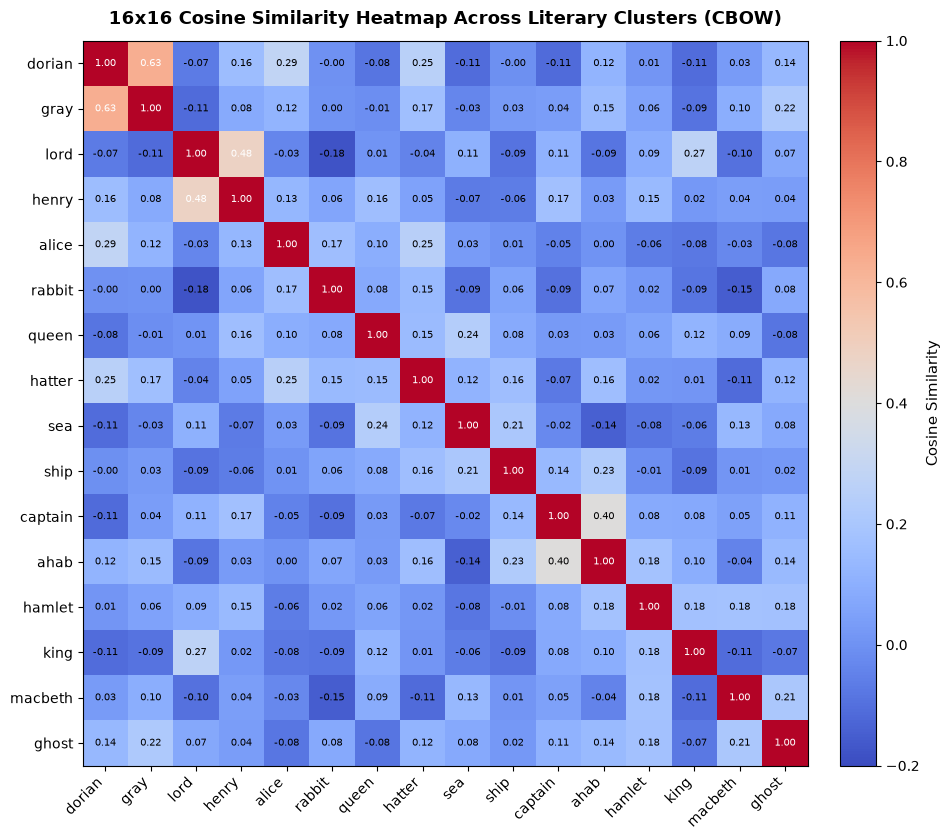

In [5]:
heatmap_words = [
    # Cluster 1: Dorian Gray
    "dorian", "gray", "lord", "henry",
    # Cluster 2: Alice in Wonderland
    "alice", "rabbit", "queen", "hatter",
    # Cluster 3: Moby Dick
    "sea", "ship", "captain", "ahab",
    # Cluster 4: Shakespearean Drama
    "hamlet", "king", "macbeth", "ghost",
]

# Filter words present in vocabulary
heatmap_words = [w for w in heatmap_words if w in bow_model.dataset.stoi]

# Compute pairwise cosine similarity matrix
embeddings = np.array([bow_model.get_embedding(w) for w in heatmap_words])
norms = np.linalg.norm(embeddings, axis=1, keepdims=True)
norm_embs = embeddings / np.where(norms == 0, 1e-8, norms)
sim_matrix = np.dot(norm_embs, norm_embs.T)

plt.figure(figsize=(9.5, 8.5))
im = plt.imshow(sim_matrix, cmap="coolwarm", vmin=-0.2, vmax=1.0)
cbar = plt.colorbar(im, fraction=0.046, pad=0.04)
cbar.set_label("Cosine Similarity", fontsize=11)

plt.xticks(range(len(heatmap_words)), heatmap_words, rotation=45, ha="right", fontsize=10)
plt.yticks(range(len(heatmap_words)), heatmap_words, fontsize=10)
plt.title("16x16 Cosine Similarity Heatmap Across Literary Clusters (CBOW)", fontsize=13, fontweight="bold", pad=12)

for r in range(len(heatmap_words)):
    for c in range(len(heatmap_words)):
        val = sim_matrix[r, c]
        txt_color = "white" if abs(val) > 0.45 else "black"
        plt.text(c, r, f"{val:.2f}", ha="center", va="center", color=txt_color, fontsize=7.5)

plt.tight_layout()
plt.show()


## 4. Live Rotatable 3D Pointplot (Plotly WebGL)

Interactive 3D embedding space rendered using Plotly. You can rotate 360° with mouse click-and-drag, zoom with the scroll wheel, and hover over individual points for details.


In [6]:
clusters_3d = {
    "Dorian Gray / Wilde": {
        "words": ["dorian", "gray", "lord", "henry", "art", "beauty", "portrait"],
        "color": "#e74c3c",
    },
    "Alice in Wonderland": {
        "words": ["alice", "rabbit", "queen", "king", "cat", "hatter", "door"],
        "color": "#27ae60",
    },
    "Moby Dick / Nautical": {
        "words": ["sea", "ship", "ocean", "water", "ahab", "captain", "deck"],
        "color": "#2980b9",
    },
    "Shakespearean Drama": {
        "words": ["hamlet", "macbeth", "prince", "ghost", "sword", "crown", "lord"],
        "color": "#8e44ad",
    },
}

all_words = []
cluster_names = []
colors = []

for cname, cinfo in clusters_3d.items():
    for w in cinfo["words"]:
        if w in bow_model.dataset.stoi and w not in all_words:
            all_words.append(w)
            cluster_names.append(cname)
            colors.append(cinfo["color"])

word_vectors = np.array([bow_model.get_embedding(w) for w in all_words])
pca_3d = PCA(n_components=3, random_state=42)
coords_3d = pca_3d.fit_transform(word_vectors)
var_ratio_3d = pca_3d.explained_variance_ratio_
print(f"3D PCA Explained Variance: {var_ratio_3d[0]:.2%}, {var_ratio_3d[1]:.2%}, {var_ratio_3d[2]:.2%} (Total: {var_ratio_3d.sum():.2%})")

fig = go.Figure()
for cname, cinfo in clusters_3d.items():
    mask = [i for i, c in enumerate(cluster_names) if c == cname]
    if not mask:
        continue
    fig.add_trace(go.Scatter3d(
        x=coords_3d[mask, 0],
        y=coords_3d[mask, 1],
        z=coords_3d[mask, 2],
        mode="markers+text",
        name=cname,
        text=[all_words[i] for i in mask],
        textposition="top center",
        textfont=dict(size=11, color="black", family="Arial Black"),
        marker=dict(
            size=7,
            color=cinfo["color"],
            opacity=0.85,
            line=dict(color="white", width=1.5),
        ),
        hovertemplate="<b>%{text}</b><br>Cluster: " + cname + "<br>PCA 1: %{x:.3f}<br>PCA 2: %{y:.3f}<br>PCA 3: %{z:.3f}<extra></extra>",
    ))

connected_pairs = [
    ("dorian", "gray", "#e74c3c"),
    ("lord", "henry", "#e74c3c"),
    ("alice", "rabbit", "#27ae60"),
    ("king", "queen", "#27ae60"),
    ("captain", "ahab", "#2980b9"),
    ("sea", "ship", "#2980b9"),
    ("hamlet", "ghost", "#8e44ad"),
    ("macbeth", "sword", "#8e44ad"),
]

for w1, w2, col in connected_pairs:
    if w1 in all_words and w2 in all_words:
        idx1, idx2 = all_words.index(w1), all_words.index(w2)
        fig.add_trace(go.Scatter3d(
            x=[coords_3d[idx1, 0], coords_3d[idx2, 0]],
            y=[coords_3d[idx1, 1], coords_3d[idx2, 1]],
            z=[coords_3d[idx1, 2], coords_3d[idx2, 2]],
            mode="lines",
            line=dict(color=col, width=3, dash="dash"),
            hoverinfo="none",
            showlegend=False,
        ))

fig.update_layout(
    title=dict(
        text="<b>Interactive 3D Word Embeddings Space (Continuous Bag-of-Words)</b><br><sup>Drag with left-click to rotate 360°, scroll to zoom, right-click to pan</sup>",
        x=0.5,
        font=dict(size=14),
    ),
    scene=dict(
        xaxis=dict(title=f"PCA 1 ({var_ratio_3d[0]:.1%})", backgroundcolor="#f7f9fa", gridcolor="#e1e8ed"),
        yaxis=dict(title=f"PCA 2 ({var_ratio_3d[1]:.1%})", backgroundcolor="#f7f9fa", gridcolor="#e1e8ed"),
        zaxis=dict(title=f"PCA 3 ({var_ratio_3d[2]:.1%})", backgroundcolor="#f7f9fa", gridcolor="#e1e8ed"),
        camera=dict(eye=dict(x=1.6, y=1.6, z=1.2)),
    ),
    width=900,
    height=650,
    margin=dict(l=0, r=0, b=0, t=60),
    legend=dict(x=0.02, y=0.98, bgcolor="rgba(255, 255, 255, 0.8)"),
)
fig.show()


3D PCA Explained Variance: 10.30%, 8.56%, 7.59% (Total: 26.44%)


## 5. 2D PCA Semantic Projection Map

2D projection onto the first two principal components, showing the clear spatial separation between distinct literary domains.


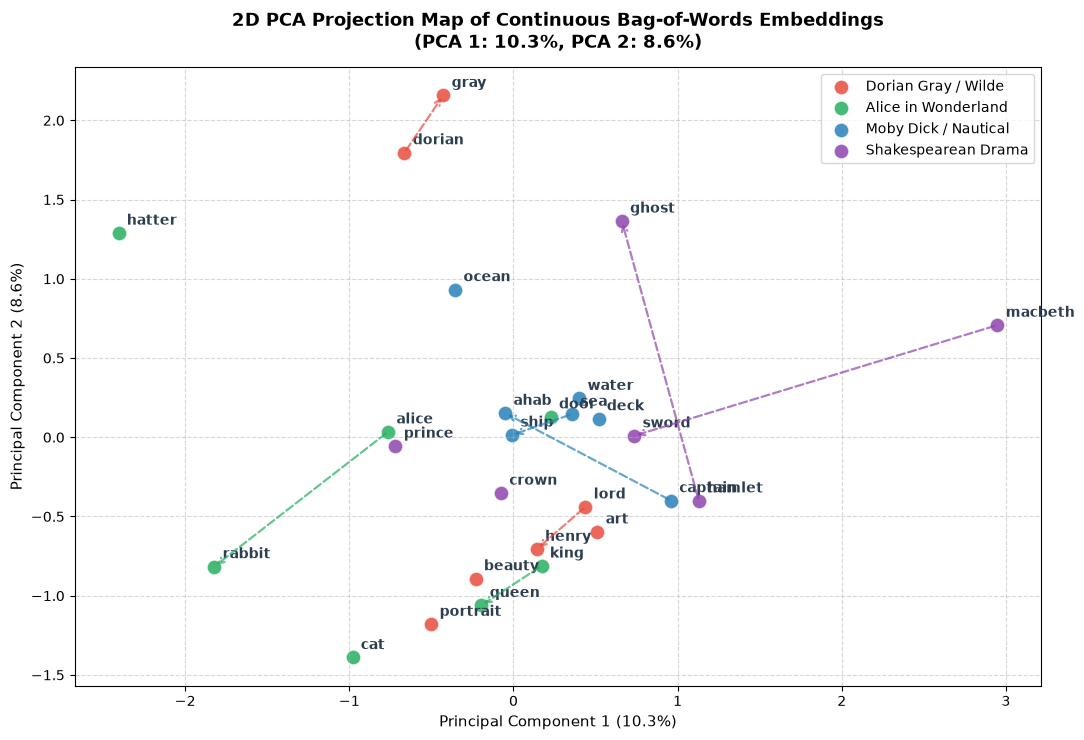

In [7]:
pca_2d = PCA(n_components=2, random_state=42)
coords_2d = pca_2d.fit_transform(word_vectors)
var_ratio_2d = pca_2d.explained_variance_ratio_

plt.figure(figsize=(11, 7.5))
plt.title(f"2D PCA Projection Map of Continuous Bag-of-Words Embeddings\n(PCA 1: {var_ratio_2d[0]:.1%}, PCA 2: {var_ratio_2d[1]:.1%})",
          fontsize=13, fontweight="bold", pad=14)

for cname, cinfo in clusters_3d.items():
    mask = [i for i, c in enumerate(cluster_names) if c == cname]
    if not mask:
        continue
    plt.scatter(
        coords_2d[mask, 0],
        coords_2d[mask, 1],
        c=cinfo["color"],
        label=cname,
        s=120,
        alpha=0.85,
        edgecolors="white",
        linewidth=1.2,
    )
    for idx in mask:
        plt.annotate(
            all_words[idx],
            xy=(coords_2d[idx, 0], coords_2d[idx, 1]),
            xytext=(6, 6),
            textcoords="offset points",
            fontsize=10,
            fontweight="bold",
            color="#2c3e50",
        )

for w1, w2, col in connected_pairs:
    if w1 in all_words and w2 in all_words:
        idx1, idx2 = all_words.index(w1), all_words.index(w2)
        plt.annotate(
            "",
            xy=(coords_2d[idx2, 0], coords_2d[idx2, 1]),
            xytext=(coords_2d[idx1, 0], coords_2d[idx1, 1]),
            arrowprops=dict(arrowstyle="->", color=col, lw=1.6, ls="--", alpha=0.7),
        )

plt.xlabel(f"Principal Component 1 ({var_ratio_2d[0]:.1%})", fontsize=11)
plt.ylabel(f"Principal Component 2 ({var_ratio_2d[1]:.1%})", fontsize=11)
plt.grid(True, linestyle="--", alpha=0.5)
plt.legend(frameon=True, facecolor="white", edgecolor="#ccc", fontsize=10, loc="best")
plt.tight_layout()
plt.show()


## 6. Vector Analogy Arithmetic ($A : B :: C : ?$)

One of the landmark discoveries in distributed representation literature (Mikolov et al., 2013, *Distributed Representations of Words and Phrases and their Compositionality*) is that word embeddings capture **linear regularities**:

$$\vec{w}_{\text{target}} = \vec{w}_B - \vec{w}_A + \vec{w}_C \approx \vec{w}_D$$

For instance, the canonical example: $\vec{w}_{\text{king}} - \vec{w}_{\text{man}} + \vec{w}_{\text{woman}} \approx \vec{w}_{\text{queen}}$.

Below, we implement an analogy solver that calculates $\arg\max_{w \notin \{A, B, C\}} \cos(\vec{w}, \vec{w}_B - \vec{w}_A + \vec{w}_C)$ across the entire vocabulary.


In [8]:
def solve_analogy(model, word_a: str, word_b: str, word_c: str, top_k: int = 5) -> list[tuple[str, float]]:
    """
    Solves word analogy queries of the form: A is to B as C is to ?
    Computes: Target = Emb(B) - Emb(A) + Emb(C)
    Returns top_k nearest neighbors by cosine similarity, excluding input words.
    """
    wa, wb, wc = word_a.lower(), word_b.lower(), word_c.lower()
    ea = model.get_embedding(wa)
    eb = model.get_embedding(wb)
    ec = model.get_embedding(wc)

    if ea is None or eb is None or ec is None:
        missing = [w for w, e in [(wa, ea), (wb, eb), (wc, ec)] if e is None]
        print(f"Warning: Tokens not in vocabulary: {missing}")
        return []

    target_vec = eb - ea + ec
    norm = np.linalg.norm(target_vec)
    if norm > 0:
        target_vec = target_vec / norm

    exclude = {wa, wb, wc}
    itos = model.dataset.itos

    # Vectorized similarity against all vocabulary tokens
    with torch.no_grad():
        weights = model.model.in_embedding.weight.detach().cpu().numpy()
        wnorms = np.linalg.norm(weights, axis=1, keepdims=True)
        wnorms = np.where(wnorms == 0, 1e-8, wnorms)
        norm_weights = weights / wnorms
        sims = np.dot(norm_weights, target_vec)

    top_indices = np.argsort(-sims)
    results = []
    for idx in top_indices:
        cand = itos[idx]
        if cand not in exclude:
            results.append((cand, float(sims[idx])))
            if len(results) >= top_k:
                break
    return results

# Benchmark analogy queries
analogy_tests = [
    ("man", "king", "woman", "queen", "Royalty / Gender (man : king :: woman : queen)"),
    ("father", "son", "mother", "daughter", "Family Relations (father : son :: mother : daughter)"),
    ("lord", "he", "lady", "she", "Title / Pronouns (lord : he :: lady : she)"),
    ("sea", "ship", "road", "carriage", "Domain / Context (sea : ship :: road : carriage)"),
    ("dorian", "gray", "moby", "dick", "Literary Titular Names (dorian : gray :: moby : dick)"),
    ("good", "better", "bad", "worse", "Comparative Degree (good : better :: bad : worse)"),
]

analogy_rows = []
for wa, wb, wc, expected, desc in analogy_tests:
    preds = solve_analogy(bow_model, wa, wb, wc, top_k=3)
    if preds:
        top1_word, top1_score = preds[0]
        top_formatted = ", ".join([f"{w} ({s:+.3f})" for w, s in preds])
        is_match = "Exact Match" if top1_word == expected else ("In Top 3" if any(w == expected for w, _ in preds) else "Semantic Neighbor")
    else:
        top1_word, top1_score, top_formatted, is_match = "N/A", 0.0, "N/A", "Missing"

    analogy_rows.append({
        "Analogy Formulation": f"{wa} : {wb} :: {wc} : ?",
        "Expected": expected,
        "Top Prediction": f"{top1_word} ({top1_score:+.3f})",
        "Top-3 Candidates": top_formatted,
        "Evaluation": is_match,
        "Description": desc,
    })

df_analogies = pd.DataFrame(analogy_rows)
display(df_analogies)


,Analogy Formulation,Expected,Top Prediction,Top-3 Candidates,Evaluation,Description
0,man : king :: woman : ?,queen,assyria (+0.389),"assyria (+0.389), babylon (+0.370), babylons (...",Semantic Neighbor,Royalty / Gender (man : king :: woman : queen)
1,father : son :: mother : ?,daughter,daughter (+0.460),"daughter (+0.460), nebat (+0.393), ishmael (+0...",Exact Match,Family Relations (father : son :: mother : dau...
2,lord : he :: lady : ?,she,middleton (+0.481),"middleton (+0.481), russell (+0.463), russells...",Semantic Neighbor,Title / Pronouns (lord : he :: lady : she)
3,sea : ship :: road : ?,carriage,drifts (+0.369),"drifts (+0.369), juliet (+0.368), vent (+0.354)",Semantic Neighbor,Domain / Context (sea : ship :: road : carriage)
4,dorian : gray :: moby : ?,dick,dick (+0.498),"dick (+0.498), trials (+0.409), asias (+0.407)",Exact Match,Literary Titular Names (dorian : gray :: moby ...
5,good : better :: bad : ?,worse,than (+0.412),"than (+0.412), 2000 (+0.377), worse (+0.362)",In Top 3,Comparative Degree (good : better :: bad : worse)


## 7. Geometric Semantic Offsets (Parallel Relation Vectors in 2D Space)

In literature (e.g., Penningston et al. GloVe 2014, Goldberg & Levy 2014), the algebraic property of analogies is visualized by plotting paired semantic terms in 2D space. If the model has learned the gender/relation dimension effectively, the directed difference vectors (arrows connecting masculine terms to feminine terms) will point in **approximately parallel directions** across distinct concepts.


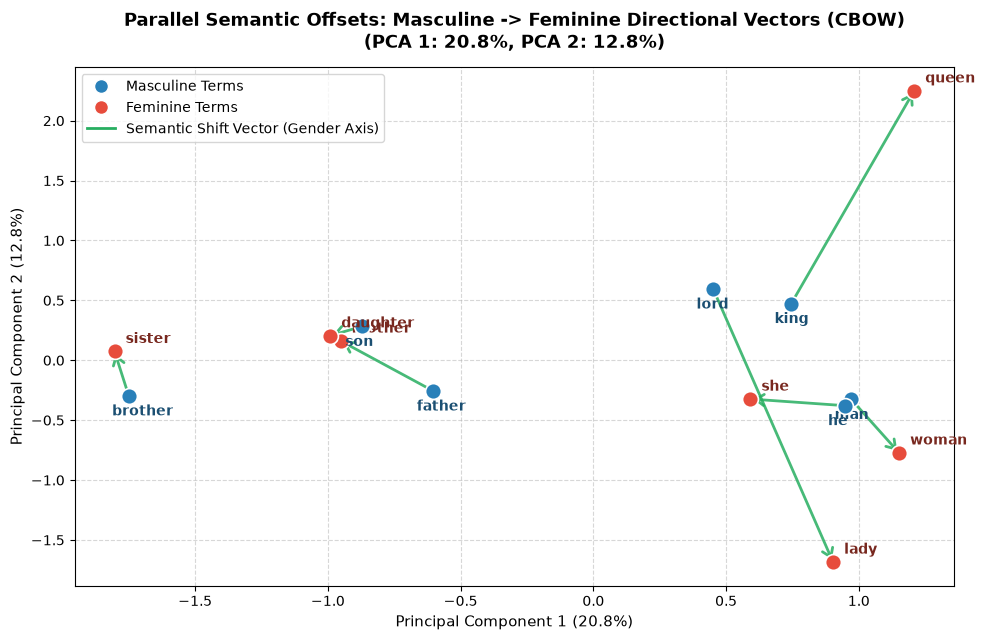

In [9]:
# Semantic pairs with consistent directional relationship (e.g. Masculine -> Feminine)
analogy_pairs = [
    ("man", "woman"),
    ("king", "queen"),
    ("lord", "lady"),
    ("father", "mother"),
    ("son", "daughter"),
    ("brother", "sister"),
    ("he", "she"),
]

# Filter pairs present in vocabulary
valid_pairs = [(m, f) for m, f in analogy_pairs if m in bow_model.dataset.stoi and f in bow_model.dataset.stoi]
pair_words = list(dict.fromkeys([w for p in valid_pairs for w in p]))

pair_vectors = np.array([bow_model.get_embedding(w) for w in pair_words])
pca_pairs = PCA(n_components=2, random_state=42)
coords_pairs = pca_pairs.fit_transform(pair_vectors)
word2coord = {w: coords_pairs[i] for i, w in enumerate(pair_words)}
var_ratio_pairs = pca_pairs.explained_variance_ratio_

plt.figure(figsize=(10, 6.5))
plt.title("Parallel Semantic Offsets: Masculine -> Feminine Directional Vectors (CBOW)\n" +
          f"(PCA 1: {var_ratio_pairs[0]:.1%}, PCA 2: {var_ratio_pairs[1]:.1%})",
          fontsize=13, fontweight="bold", pad=14)

for m, f in valid_pairs:
    pos_m = word2coord[m]
    pos_f = word2coord[f]

    # Plot points
    plt.scatter(pos_m[0], pos_m[1], color="#2980b9", s=130, zorder=3, edgecolors="white", linewidth=1.2)
    plt.scatter(pos_f[0], pos_f[1], color="#e74c3c", s=130, zorder=3, edgecolors="white", linewidth=1.2)

    # Labels
    plt.annotate(m, xy=pos_m, xytext=(-12, -14), textcoords="offset points", fontsize=10, fontweight="bold", color="#1b4f72")
    plt.annotate(f, xy=pos_f, xytext=(8, 6), textcoords="offset points", fontsize=10, fontweight="bold", color="#78281f")

    # Directed arrow from masculine to feminine
    plt.annotate(
        "",
        xy=pos_f,
        xytext=pos_m,
        arrowprops=dict(arrowstyle="->,head_width=0.4,head_length=0.6", color="#27ae60", lw=2.0, ls="-", alpha=0.85),
        zorder=2,
    )

# Custom legend handles
from matplotlib.lines import Line2D
legend_elements = [
    Line2D([0], [0], marker="o", color="w", markerfacecolor="#2980b9", markersize=10, label="Masculine Terms"),
    Line2D([0], [0], marker="o", color="w", markerfacecolor="#e74c3c", markersize=10, label="Feminine Terms"),
    Line2D([0], [0], color="#27ae60", lw=2, label="Semantic Shift Vector (Gender Axis)"),
]
plt.legend(handles=legend_elements, loc="best", facecolor="white", edgecolor="#ccc", fontsize=10)

plt.xlabel(f"Principal Component 1 ({var_ratio_pairs[0]:.1%})", fontsize=11)
plt.ylabel(f"Principal Component 2 ({var_ratio_pairs[1]:.1%})", fontsize=11)
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()


## 8. Model Vector Export

Save the trained embeddings to disk in standard Word2Vec text format for downstream tasks or external evaluation.


In [10]:
# Save the trained BoW embeddings to disk in standard Word2Vec format
output_file = bow_model.save_embeddings(
    output_dir=embeddings_dir,
    filename="bow_embeddings.txt",
    format="word2vec",
)
print(f"\nContinuous Bag-of-Words embeddings successfully exported to: {output_file}")


2026-10-24 19:21:37 [INFO] [BoW]: Using in_embedding weights across 23984 tokens (tied_weights=True).


2026-10-24 19:21:39 [INFO] [BoW]: BoW Word embeddings successfully saved to 'C:\Users\utente\repos\word2vec\embeddings\bow_embeddings.txt' (23984 words, dim=128, format=word2vec).



Continuous Bag-of-Words embeddings successfully exported to: C:\Users\utente\repos\word2vec\embeddings\bow_embeddings.txt
